# Reading the GiD / Iber mesh format with `pyramids-mesh`

The **GiD** ASCII mesh format (CIMNE's format, and the one the **Iber** 2D hydraulic model exports, since Iber is built on GiD) stores a mesh as `MESH ... dimension D ElemType T Nnode N`, then a `Coordinates` block of `node_id x y [z]` and an `Elements` block of `el_id n1..nN [mat]`, all 1-based with `#` comments. It shares the `.msh` extension with Gmsh, so the driver must be given explicitly. The sample is a 2D triangular mesh of a tube cross-section. `pyramids-mesh` reads it into a `pyramids.netcdf.ugrid` object.

## 1. Plotting backend and a figure helper

`pyramids-mesh` draws through **cleopatra** (reached via pyramids), which builds its own matplotlib figure. Under the non-interactive `Agg` backend nothing embeds on its own, so we define a tiny `show()` helper that grabs the current figure and displays it as an inline PNG. Call it right after every plot.

In [1]:
import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg")
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display


def show():
    """Render the current matplotlib figure inline as an embedded PNG."""
    from io import BytesIO

    buf = BytesIO()
    plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all")
    buf.seek(0)
    display(Image(data=buf.read()))

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pathlib import Path

import numpy as np
from pyramids.netcdf.ugrid import UgridDataset

DATA = Path("../../examples/data")
MESH = DATA / "gid" / "tube_2D_spline.GiD.msh"
MESH.name, MESH.exists()

('tube_2D_spline.GiD.msh', True)

The file is `tube_2D_spline.GiD.msh` in the `gid/` sub-folder (see `SOURCE.txt`). The tuple confirms it resolves.

## 3. Read the file in one call

Because `.msh` is shared with Gmsh, we **must** pass `driver="gid"` — suffix sniffing alone could not tell the two apart. The sample uses `ElemType Triangle` with `Nnode 6` (quadratic triangles); the reader keeps the **three corner nodes** of each element, giving linear triangles.

In [3]:
ds = UgridDataset.read_file(MESH, driver="gid")
ds

UgridDataset(mesh='mesh2d', n_node=943, n_face=414, n_edge=0, variables=[])

A `UgridDataset` with the tube's nodes and triangular elements — the Iber/GiD mesh is now a generic pyramids object.

## 4. Explore the dataset

A handful of attributes describe what we loaded: node and face counts, the coordinate reference system, the names of any data variables, and the spatial extent.

In [4]:
import pandas as pd
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "data_variable_names": ds.data_variable_names,
    "bounds": ds.bounds,
}).to_frame("value")

,value
n_node,943
n_face,414
crs,None
epsg,None
data_variable_names,[]
bounds,"(0.0, -20.0, 37.8843, 11.8444)"


**943 nodes, 414 faces.** `crs`/`epsg` are `None` — the GiD format records no EPSG. Crucially, `data_variable_names` is **empty**: unlike the surface formats (PLY/TIN/OBJ), this GiD mesh carries **no `node_z`** — it is a purely planar 2D mesh with no elevation column, so there is no node field at all.

## 5. A statistical summary of the fields

`summary()` returns a pandas frame with one row per data variable (count, min, max, mean, std).

In [5]:
ds.summary()

,count,min,max,mean,std
variable,,,,,


The summary frame is **empty** (right columns, no rows): there are genuinely no data variables to summarise on this bare 2D mesh. This is the honest answer, not an error — we create a field to plot in the next step.

## 6. The underlying `Mesh2d` geometry

`ds.mesh` is the `Mesh2d` object carrying the raw topology: node coordinates, the face-node connectivity table of shape `(n_face, k)` (row *i* lists the node indices of cell *i*), per-face areas, and cell centroids.

In [6]:
mesh = ds.mesh
fnc = np.asarray(mesh.face_node_connectivity.data)
areas = np.asarray(mesh.face_areas)
centroids = np.asarray(mesh.face_centroids)  # shape (2, n_face)
pd.Series({
    "connectivity_shape": fnc.shape,
    "nodes_per_face_k": fnc.shape[1],
    "area_min": float(areas.min()),
    "area_max": float(areas.max()),
    "centroids_shape": centroids.shape,
    "mesh_bounds": mesh.bounds,
}).to_frame("value")

,value
connectivity_shape,"(414, 3)"
nodes_per_face_k,3
area_min,0.117214
area_max,3.045124
centroids_shape,"(2, 414)"
mesh_bounds,"(0.0, -20.0, 37.8843, 11.8444)"


`k = 3` — linear triangles (the reader dropped the mid-edge nodes of the original quadratic elements). The node count (943) exceeds three times the face count because those mid-edge nodes remain in the coordinate table even though the connectivity uses only the corners. The area range reflects a genuinely graded 2D hydraulic mesh.

## 7. The mesh outline (wireframe)

`plot_outline()` draws the bare cell edges, with no field attached — the quickest look at the raw geometry this driver produced.

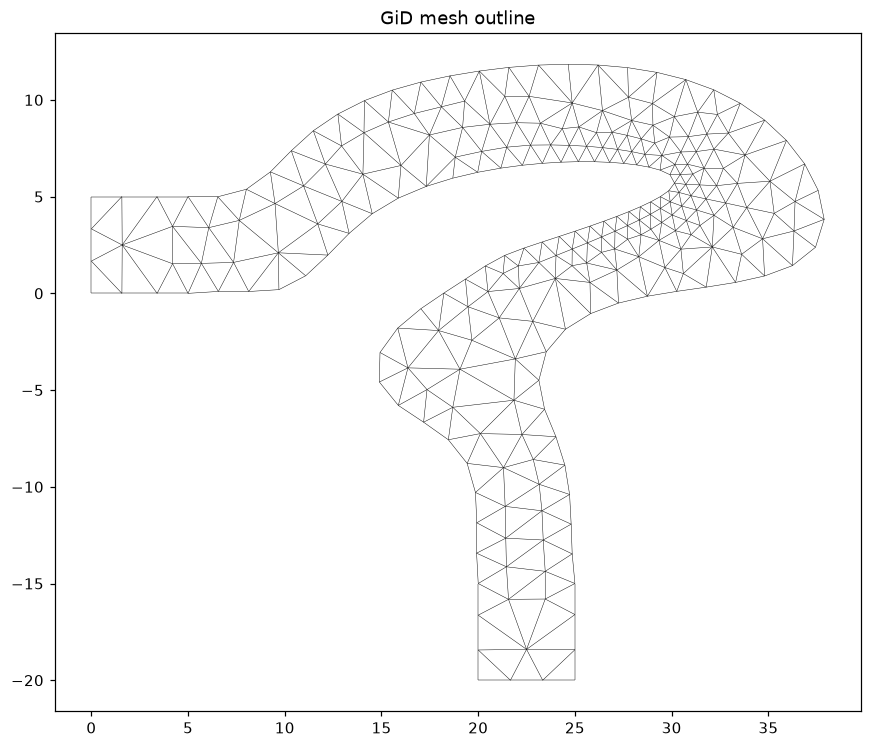

In [7]:
g = ds.plot_outline()
g.ax.set_title("GiD mesh outline")
show()

The wireframe shows the tube cross-section as a graded triangular mesh — finer where the Iber/GiD mesher refined the geometry, coarser elsewhere.

## 8. A data map: attach and colour by cell area

These surface formats carry no field data, so there is nothing to colour by yet. We attach a derived **`cell_area`** variable at the face location and plot it — turning the geometry into a proper choropleth.

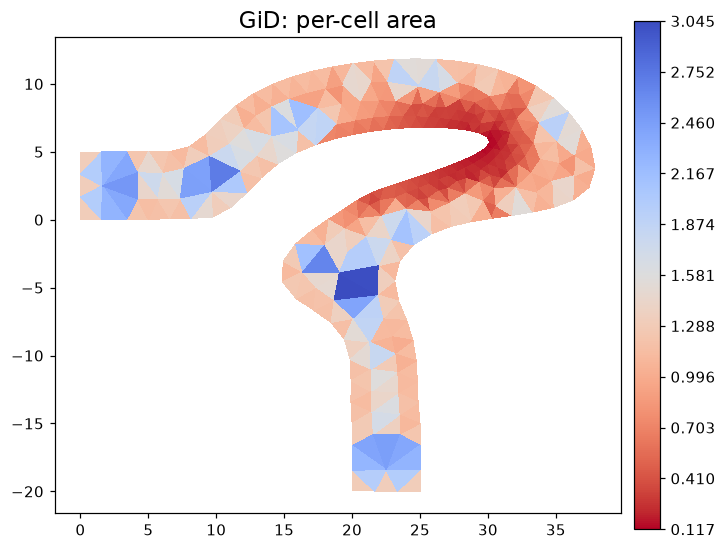

In [8]:
d2 = ds.with_variable("cell_area", np.asarray(mesh.face_areas), location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True,
        title="GiD: per-cell area")
show()

With no field in the file, `cell_area` is the natural first thing to colour by. The map exposes the mesh grading directly: small dark cells in the refined zones, larger bright cells where the mesh is coarse — exactly the information a modeller checks before running Iber.

## 9. GIS operations, for free

Because a `UgridDataset` is a first-class pyramids object, a whole GIS toolkit comes along. First, every face as a row in a GeoDataFrame.

In [9]:
gdf = ds.to_geodataframe()
print(gdf.shape, list(gdf.columns))
gdf.head()

(414, 1) ['geometry']


,geometry
0,"POLYGON ((29.9101 6.13454, 30.1478 5.70044, 30..."
1,"POLYGON ((30.1478 5.70044, 29.8499 5.3035, 30...."
2,"POLYGON ((29.8499 5.3035, 29.4133 4.99884, 29...."
3,"POLYGON ((30.4444 6.14501, 30.1478 5.70044, 30..."
4,"POLYGON ((29.9101 6.13454, 30.4444 6.14501, 30..."


414 triangle polygons, one per element — the hydraulic mesh as a vector layer, with no CRS attached (matching `crs=None`).

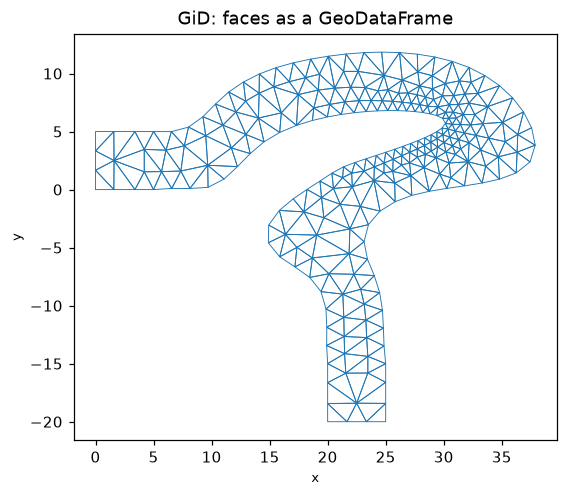

In [10]:
ax = gdf.boundary.plot(color="#1f77b4", linewidth=0.6)
ax.set_title("GiD: faces as a GeoDataFrame")
ax.set_aspect("equal")
show()

The GeoDataFrame is the gateway to the entire shapely/geopandas ecosystem — spatial joins, buffering, reprojection, export to any OGR vector format — all on the mesh cells.

### Bounding polygon

`bounding_polygon()` returns a single shapely geometry: the dissolved outer footprint of the mesh.

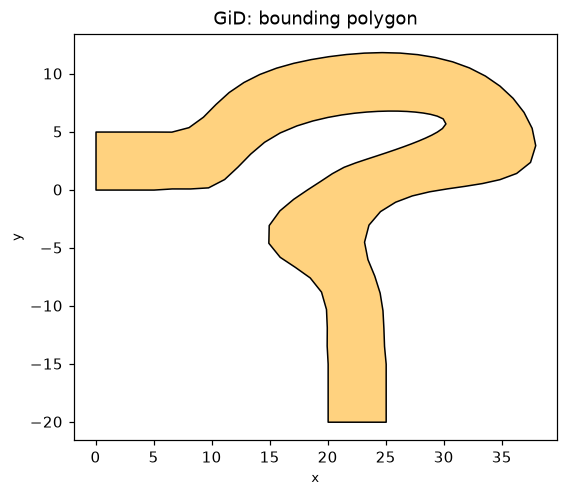

Polygon 384.8341


In [11]:
import geopandas as gpd

poly = ds.bounding_polygon()
ax = gpd.GeoSeries([poly]).plot(facecolor="#ffd27f", edgecolor="k")
ax.set_title("GiD: bounding polygon")
ax.set_aspect("equal")
show()
print(type(poly).__name__, round(poly.area, 4))

The bounding polygon dissolves the 414 triangles into the single outer boundary of the tube cross-section.

### Derived topology and connectivity

A few more derived quantities are a method call away. `circumcenters()` is defined only for triangular meshes; `exterior_edges()` indexes the boundary edges; `connected_components()` labels disjoint pieces; `sparse_adjacency()` is the face-to-face graph as a sparse matrix.

In [12]:
try:
    cc = np.asarray(ds.circumcenters())
    circ = f"{cc.shape} array"
except ValueError as e:
    circ = f"skipped ({e})"
ext = np.asarray(ds.exterior_edges())
comp = np.asarray(ds.connected_components())
adj = ds.sparse_adjacency()
pd.Series({
    "circumcenters": circ,
    "n_boundary_edges": int(ext.size),
    "n_connected_components": int(np.unique(comp).size),
    "adjacency_shape": adj.shape,
    "adjacency_nnz": int(adj.nnz),
}).to_frame("value")

,value
circumcenters,"(414, 2) array"
n_boundary_edges,114
n_connected_components,1
adjacency_shape,"(414, 414)"
adjacency_nnz,1128


Circumcenters are defined (triangular mesh) — these are the natural control points for a finite-volume hydraulic solver. The boundary-edge count traces the domain outline, and the adjacency matrix is the cell-connectivity graph the solver would march over.

### Cropping to a bounding box

`crop(bbox=...)` keeps the faces that fall within (or touch) a rectangle, returning a new `UgridDataset`. Here we crop to the left portion of the extent and redraw it.

faces: 414 -> 162


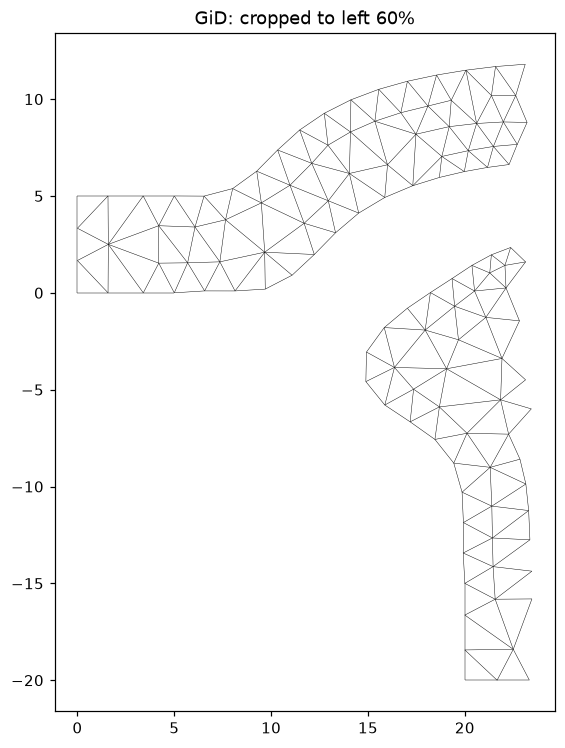

In [13]:
xmin, ymin, xmax, ymax = ds.bounds
bbox = (xmin, ymin, xmin + 0.6 * (xmax - xmin), ymax)
cropped = ds.crop(bbox=bbox)
print(f"faces: {ds.n_face} -> {cropped.n_face}")
gc = cropped.plot_outline()
gc.ax.set_title("GiD: cropped to left 60%")
show()

Cropping to the left 60% of the extent carves out a spatial slice of the tube mesh — useful for isolating a reach or a region of interest before analysis.

### Round-tripping and the xarray view

`to_file(..., driver=...)` writes the mesh back out in any writable driver (here the solver-neutral 2DM), and `to_xarray()` exposes the whole dataset as an `xarray.Dataset` for NetCDF-style analysis.

In [14]:
import tempfile

out = Path(tempfile.gettempdir()) / "roundtrip.2dm"
ds.to_file(out, driver="2dm")
xds = ds.to_xarray()
print("wrote", out.name, "bytes:", out.stat().st_size)
print(xds.dims)

wrote roundtrip.2dm bytes: 35489
FrozenMappingWarningOnValuesAccess({'mesh2d_scalar': 1, 'mesh2d_nNodes': 943, 'mesh2d_nFaces': 414, 'mesh2d_nMaxFaceNodes': 3})


The mesh survives the round-trip to a different format, and `to_xarray()` hands us a familiar labelled-array object — proof that a format-specific reader produces a fully generic, interoperable dataset.

## 10. What we skip here, and why

- **`to_crs(...)`** needs a source CRS to reproject from, but GiD files carry no georeferencing (`crs=None`), so there is nothing to reproject. Attach a CRS first if the coordinates are known to be in a specific projection.
- **`rasterize_like(...)` / `regrid(...)`** require a *reference grid* (a raster or target mesh) to sample onto; with only this standalone mesh in hand there is no target, so they are out of scope for this tutorial.

## Takeaway

A GiD/Iber `.msh` reads into a `UgridDataset` only when the driver is named explicitly (the extension collides with Gmsh). Its quadratic triangles are reduced to their corner nodes, and because it is a bare 2D hydraulic mesh it carries **no data variables at all** — the clearest contrast with the elevation-bearing surface formats. Once read, it joins the same pyramids pipeline: derive a field, map it, export it, crop it.